# Project 1 — Denoising by Design: From Classical to Learned Spatial Filters

**CS 6640 — Introduction to Digital Image Processing · Module 01 · Project 1**

| | |
|---|---|
| **Name** | Raymond Tran |
| **UID** | u1492672 |

---

## Central project question

> **How do assumptions about image corruption, neighborhood support, and parameter
> choices determine what a spatial filter suppresses or preserves — and what changes
> when the filter coefficients are learned rather than explicitly specified?**

---

## The research reasoning loop used throughout this project

```
assumption -> prediction -> controlled experiment -> evidence
          -> compare with prediction -> interpret -> revise understanding
```

Making a prediction before seeing the result helps separate reasoning from hindsight.
Comparing that prediction with experimental evidence — especially when they disagree —
is a fundamental research habit. The goal is not merely to obtain an output, but to
understand what assumptions explain the output and what evidence supports the
conclusion.

Every cell that begins with **Prediction** must be filled in *before* you run the
experiment below it. Nothing is lost by predicting wrongly; credit follows the quality
of the reasoning and the revision, not the luck of the guess.

---

## Structure and points

| Part | Title | Points |
|---|---|---:|
| 1 | Establish the experiment | 10 |
| 2 | Classical filtering toolbox | 15 |
| 3 | Match the filter to the corruption | 20 |
| 4 | Parameter sensitivity and failure | 25 |
| 5 | Learn the Gaussian smoothing kernel | 20 |
| 6 | Module synthesis | 10 |
| | **Base total** | **100** |
| — | Optional research extension | up to +10 |

The optional extension is extra credit only. Attempting it can never reduce your base
project grade.

### This notebook is also your report

You do not write a separate report document. This executed notebook, exported to
`driver.pdf`, is your report. The required report sections map onto the parts below:

| Required report section | Where it lives in this notebook |
|---|---|
| Introduction | Introduction (immediately below) |
| Methods | Part 1 and Part 2 |
| Results | Part 3 |
| Analysis and Parameter Sensitivity | Part 4 and Part 5 |
| Responses to Analytical Questions | Part 6 |
| Conclusions | Conclusions |

The project PDF remains the complete authoritative specification. Read it alongside
this notebook.

---

# Introduction

*Required report section: **Introduction**.*

In two or three short paragraphs, state the processing problem this project studies and
your objectives. Say what a spatial filter is being asked to do here, what "success"
would mean, and why a controlled synthetic corruption experiment is a reasonable way to
study it.

This project studies spatial filters and how their paramters (e.g. uniform vs. distance-weighted averaging) affect their effectiveness against specific corruption types. The objective is to understand how well each filter performs and what underlying mechanism makes it effective to a given corruption type. A spatial filter here is being asked to recover a clean estimate of an image from a corrupted version using a kernel. Success is measured through both visual (how well edges are preserved/if artificating occurs) and empirical evidence (PSNR).

A controlled synthetic corruption experiment is a reasonable way to study this because it provides access to the clean, original image as reference. Starting from that clean image and applying a known corruption process allows the error to be measured directly, by comparing the filter's output to the original.

In [1]:
# --- Setup -----------------------------------------------------------------
# Run this cell first. If an import fails, see Appendix A of the project PDF.

import numpy as np
import matplotlib.pyplot as plt
from scipy.ndimage import uniform_filter, gaussian_filter, median_filter

import p1_helpers as H

print(H.environment_report())
print()
print("fixed project settings")
print("  seed                    :", H.SEED)
print("  Gaussian noise sigma    :", H.GAUSSIAN_SIGMA_NOISE)
print("  impulse noise fraction  :", H.IMPULSE_AMOUNT)
print("  default boundary mode   :", H.DEFAULT_BOUNDARY)
print("  PSNR data_range         :", H.DATA_RANGE)

python      3.13.15
numpy       2.1.3
scipy       1.16.3
scikit-image 0.25.2
matplotlib  3.10.0
torch       2.11.0+cpu

fixed project settings
  seed                    : 6640
  Gaussian noise sigma    : 0.08
  impulse noise fraction  : 0.08
  default boundary mode   : reflect
  PSNR data_range         : 1.0


---

# Part 1 — Establish the experiment · **10 points**

*Required report section: **Methods** (with its supporting results).*

Before any filter is applied, the experiment itself has to be reproducible and its
assumptions have to be written down. In this part you load the two classical-section
images, standardize their representation, apply the two fixed corruption models, and
record the baseline evidence that every later comparison is measured against.

**Task-specific help.** `H.load_standard_image(name)` returns a grayscale
`float64` array in `[0, 1]`. `H.make_corruptions(img)` returns a dictionary with the
`'gaussian'` and `'impulse'` corrupted images using the fixed seed and parameters.
`H.psnr(clean, test)` calls `skimage.metrics.peak_signal_noise_ratio` with
`data_range=1.0` — the correct convention for images standardized to `[0, 1]`.
`H.crop(img, image_name=...)` extracts the same diagnostic region from any image of the
same size, so visual comparisons are always at the same location.

In [2]:
# 1a. Load and standardize the two classical-section images, and record the
#     representation facts you are asked to report.

images = {name: H.load_standard_image(name) for name in ["camera", "coins"]}

rows = []
for name, img in images.items():
    d = H.describe_image(img, name)
    rows.append([d["name"], d["shape"], d["dtype"], d["min"], d["max"]])

print(H.results_table(rows, ["image", "shape", "dtype", "min", "max"]))

| image | shape | dtype | min | max |
|---|---|---|---|---|
| camera | (512, 512) | float64 | 0.0000 | 1.000 |
| coins | (303, 384) | float64 | 0.0039 | 0.9882 |


In [3]:
# 1b. Apply the two fixed corruption models and record the baseline PSNR of each
#     corrupted image against its clean ground truth.

corrupted = {name: H.make_corruptions(img) for name, img in images.items()}

baseline_rows = []
for name, img in images.items():
    for corruption, noisy in corrupted[name].items():
        baseline_rows.append([name, corruption, H.psnr(img, noisy)])

baseline_table = H.results_table(baseline_rows, ["image", "corruption", "baseline PSNR (dB)"])
print(baseline_table)

| image | corruption | baseline PSNR (dB) |
|---|---|---|
| camera | gaussian | 22.241 |
| camera | impulse | 15.724 |
| coins | gaussian | 22.021 |
| coins | impulse | 16.065 |


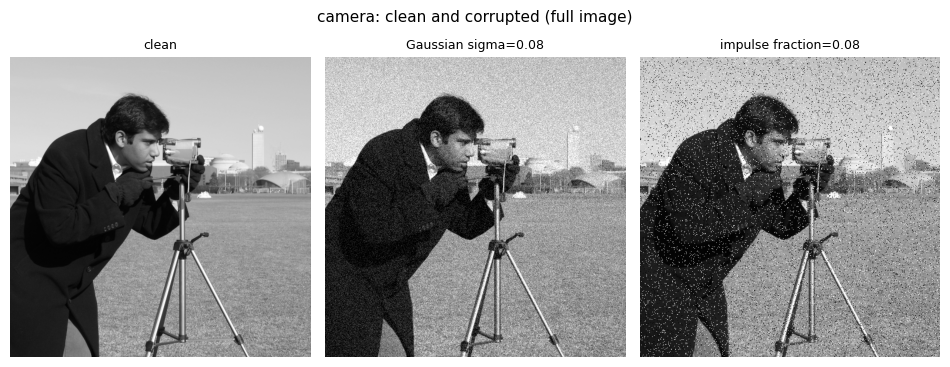

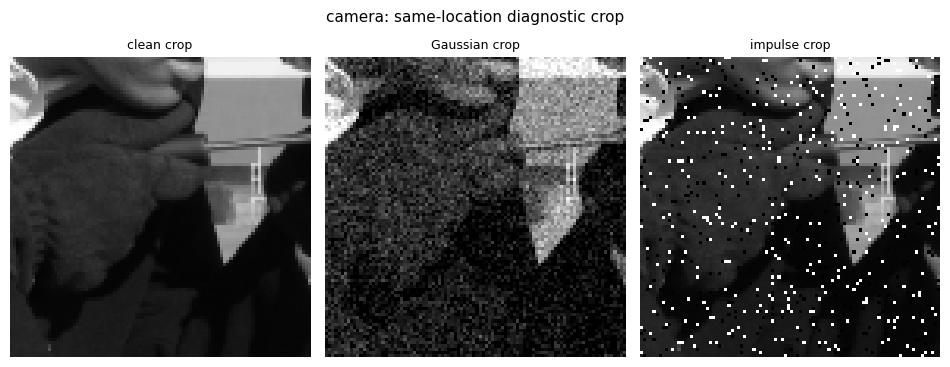

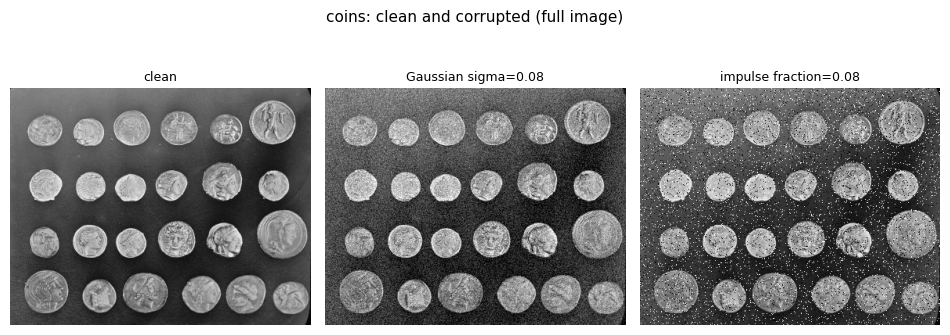

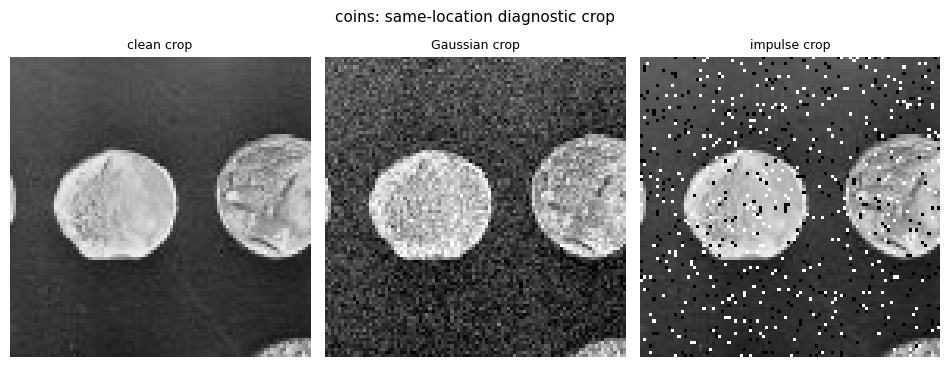

In [4]:
# 1c. Required evidence: clean, Gaussian-corrupted, impulse-corrupted, plus the
#     same-location diagnostic crop for each. Repeat for both images.

for name, img in images.items():
    H.show_images(
        [img, corrupted[name]["gaussian"], corrupted[name]["impulse"]],
        ["clean", f"Gaussian sigma={H.GAUSSIAN_SIGMA_NOISE}",
         f"impulse fraction={H.IMPULSE_AMOUNT}"],
        suptitle=f"{name}: clean and corrupted (full image)")
    H.show_images(
        [H.crop(img, image_name=name),
         H.crop(corrupted[name]["gaussian"], image_name=name),
         H.crop(corrupted[name]["impulse"], image_name=name)],
        ["clean crop", "Gaussian crop", "impulse crop"],
        suptitle=f"{name}: same-location diagnostic crop")
    plt.show()

### 1d. Record your experimental assumptions

Fill in the table from what your code actually produced. Do not transcribe numbers by
hand where a printed cell already reports them — refer to the cell instead.

| Setting | Value | Value | | |
|---|---|---|---|---|
| Image identity | Camera | Coins |
| Image dimensions | 512 by 512 |  303 by 384 |
| dtype and range after standardization | float64 (0.0000 - 1.0000) | float64 (0.0039 - 0.9882) |
| Corruption types | Gaussian/Impulse | Gaussian/Impulse |
| Corruption parameters | sigma = 0.08/fraction = 0.08 | sigma = 0.08/fraction = 0.08 |
| Random seed | 6640 | 6640 |
| Boundary convention | Reflect | Reflect |
| Range/clipping convention | corrupted images are clipped back into [0, 1]; filter outputs of inputs in[0, 1] already lie in [0, 1] and are not re-clipped|

### 1e. Why does controlled synthetic corruption give a useful experiment?

Explain, in a short paragraph, why deliberately corrupting an image whose clean version
you already have is a useful experimental design — and what that design cannot tell you
about real acquired images.

Deliberately corrupting an image allows an algorithm's denoising performance to be precisely evaluated. Since the uncorrupted original serves as a reference, the algorithm's output can be directly compared to it to measure error. However, this design cannot reveal the actual types of corruption present in real acquired images. real-world degradation is often complex and unknown, and may not align with the specific corruption the algorithm was designed or tested to correct.

---

# Part 2 — Classical filtering toolbox · **15 points**

*Required report section: **Methods** (with its supporting results).*

Apply the three classical neighborhood operations at their baseline settings using
standard library functions. You are not asked to write convolution loops or to implement
box, Gaussian, or median filtering yourself.

Baseline conditions for this part:

| Operation | Library call | Baseline setting |
|---|---|---|
| Box / mean | `scipy.ndimage.uniform_filter` | `size=5` (a 5 x 5 neighborhood) |
| Gaussian | `scipy.ndimage.gaussian_filter` | `sigma=1.0` |
| Median | `scipy.ndimage.median_filter` | `size=5` (a 5 x 5 neighborhood) |

All three take `mode='reflect'`, the default boundary convention for this project.

**Task-specific help.** `scipy.ndimage.gaussian_filter` does not take a kernel size. It
derives its support from `sigma` and its `truncate` parameter (default `truncate=4.0`),
so the discrete kernel radius is `int(truncate * sigma + 0.5)`. Report the effective
support you get, and say where it came from — the effective support of a Gaussian filter
is a consequence of the parameters, not a free choice.

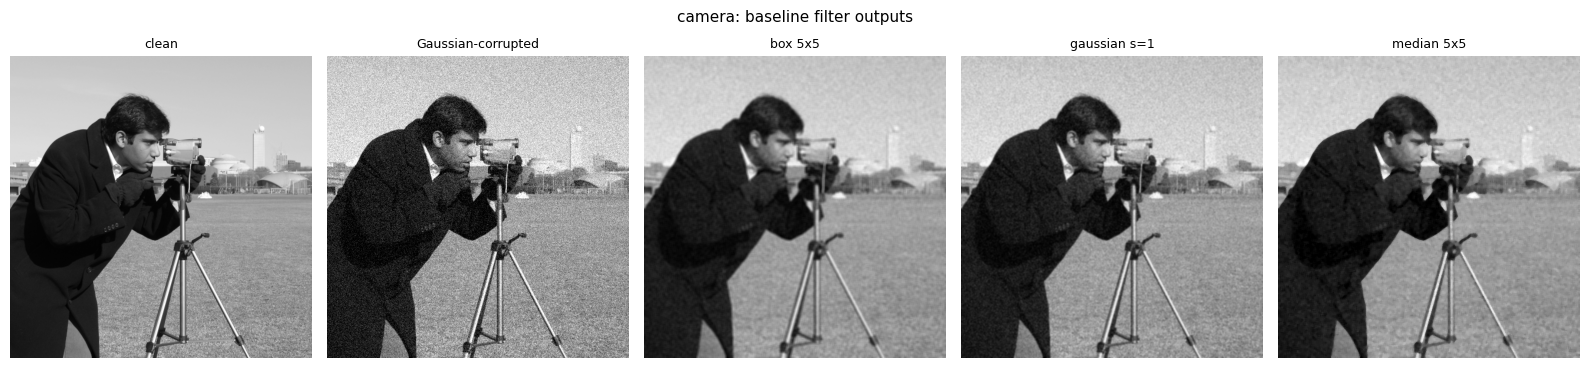

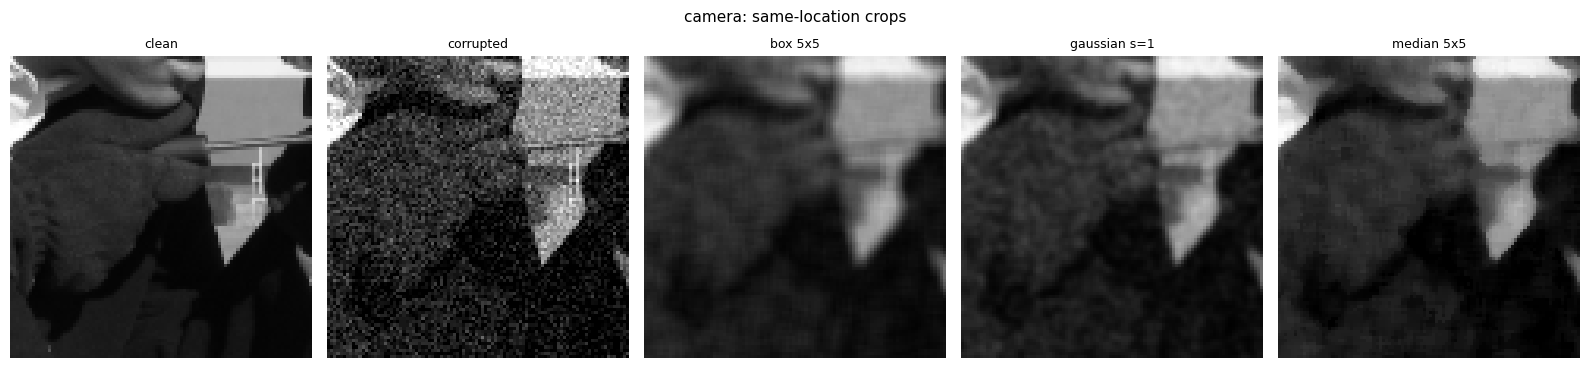

In [5]:
# 2a. Apply the three baseline filters to one corrupted image and inspect the results.

work_image = "camera"
clean = images[work_image]
noisy = corrupted[work_image]["gaussian"]

baseline_filters = {
    "box 5x5":      uniform_filter(noisy, size=5, mode=H.DEFAULT_BOUNDARY),
    "gaussian s=1": gaussian_filter(noisy, sigma=1.0, mode=H.DEFAULT_BOUNDARY),
    "median 5x5":   median_filter(noisy, size=5, mode=H.DEFAULT_BOUNDARY),
}

H.show_images([clean, noisy] + list(baseline_filters.values()),
              ["clean", "Gaussian-corrupted"] + list(baseline_filters),
              suptitle=f"{work_image}: baseline filter outputs")
H.show_images([H.crop(clean, image_name=work_image), H.crop(noisy, image_name=work_image)]
              + [H.crop(v, image_name=work_image) for v in baseline_filters.values()],
              ["clean", "corrupted"] + list(baseline_filters),
              suptitle=f"{work_image}: same-location crops")
plt.show()

In [6]:
# 2b. Report the effective support of the Gaussian filter at sigma = 1.0
#     for the truncation convention your scipy version uses.

truncate = 4.0
for sigma in [0.5, 1.0, 1.5, 2.0]:
    radius = int(truncate * sigma + 0.5)
    print(f"sigma={sigma:4.1f}   radius={radius:2d} samples   "
          f"effective support = {2*radius+1} x {2*radius+1}")

sigma= 0.5   radius= 2 samples   effective support = 5 x 5
sigma= 1.0   radius= 4 samples   effective support = 9 x 9
sigma= 1.5   radius= 6 samples   effective support = 13 x 13
sigma= 2.0   radius= 8 samples   effective support = 17 x 17


[[0.00297 0.01331 0.02194 0.01331 0.00297]
 [0.01331 0.05963 0.09832 0.05963 0.01331]
 [0.02194 0.09832 0.1621  0.09832 0.02194]
 [0.01331 0.05963 0.09832 0.05963 0.01331]
 [0.00297 0.01331 0.02194 0.01331 0.00297]]
coefficient sum: 1.0


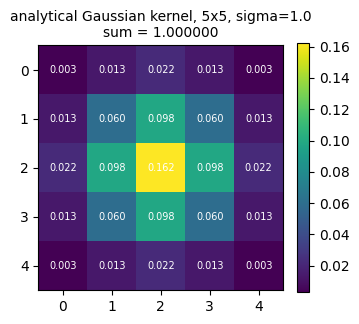

In [7]:
# 2c. Inspect the explicit normalized 5x5 analytical Gaussian kernel.
#     Keep this figure: Part 5 compares a *learned* kernel against exactly this one.

K_analytical = H.analytical_gaussian_kernel(size=5, sigma=1.0)
print(np.round(K_analytical, 5))
print("coefficient sum:", K_analytical.sum())
H.show_kernel(K_analytical, "analytical Gaussian kernel, 5x5, sigma=1.0")
plt.show()

### 2d. Characterize each operation

Complete this table from what the operations actually are, not from what the outputs
look like.

| Operation | Key parameter(s) | Neighborhood / support | Boundary handling | Expected preservation / suppression behavior |
|---|---|---|---|---|
| Box / mean | Size | 5x5 pixel neighborhood | Reflect | Suppresses random/Gaussian noise. Does not preserve sharp edges or fine texture. |
| Gaussian | Sigma value | 9x9 when sigma = 1* | Reflect | Suppresses random/Gaussian noise. Does not preserve sharp edges but smoother than the box filter\*. |
| Median | Size | 5x5 pixel neighborhood | Reflect | Suppresses salt and pepper noise and preserves edges better than the box and Gaussian filters. |

\*Derived from equation (2 * radius + 1) where radius is equal to int(truncate * sigma + 0.5). 'Truncate' in this case was 4.0 and the radius was rounded down to 4.0 (casting to int)
\*Due to the weight distribution of the kernel, blurring is less severe than with the evenly-weighted box filter.



### 2e. Gaussian separability

A 2-D Gaussian kernel factors into a horizontal 1-D Gaussian followed by a vertical one.
Briefly: (i) state why that factorization exists for the Gaussian, (ii) state what the
separable form costs for a $K \times K$ kernel on an $M \times N$ image compared with
the direct 2-D form, and (iii) say whether separability changes the *result* or only the
*work*. You are not asked to benchmark runtimes; machine-dependent timing is not the
evidence this question wants.

> Factorization for the Gaussian exists because it possesses a coefficient array of rank one. This means that the kernel can be formed by multiplying the row vector by the column vector.

> When comparing costs between the separable form and direct 2-D form, the differences become more apparent as M and N increase. The number of calculations using the separable form is equal to $M_h$ + $N_h$. On the other hand, the number calculations using the direct 2-D form is equal to $M_hN_h$. For example, a 20x20 image is only 40 multiplications with separable form but 400 multiplications with the direct 2-D form.

> Separability does not affect the result of the filtering whatsoever. Separability only makes a statement regarding the factorization of the kernel and not the function of the kernel itself.



---

# Part 3 — Match the filter to the corruption · **20 points**

*Required report section: **Results**.*

Now run the full comparison: **2 corruption models x 3 filters**, at the baseline
settings from Part 2, on both images.

**Predict first.** Do not run the comparison cell until you have written both
predictions below.

### 3a. Predictions

**For additive Gaussian corruption:** which of box, Gaussian, and median do you expect
to perform best, and *why*? Name the assumption behind your expectation.

> A Gaussian filter is best suited to additive Gaussian corruption, since its distance-weighted averaging directly matches the noise's smooth, random distribution. A box filter can also reduce Gaussian noise, but its uniform kernel blurs edges and detail more than necessary, since every pixel is treated identically. A median filter is not well suited to Gaussian noise, since it produces slight intensity variations across many pixels rather than a few high-contrast outliers. This slight variation does not establish a clear median value, causing the output to appear patchy or blocky.

**For impulse (salt-and-pepper) corruption:** which do you expect to perform best, and
*why*?

> A median filter is the optimal choice when addressing salt-and-pepper corruption. By ignoring outliers and taking the median value of the kernel, it effectively removes the high-contrast outlier pixels that salt-and-pepper corruption introduces. Both Gaussian and box filters, in contrast, smooth over the black-and-white outliers rather than removing them, smearing high-contrast areas across the image.

In [8]:
# 3b. The 2 x 3 controlled comparison. Same corruption settings, same boundary mode,
#     same crop location: only the filter changes.

def apply_baseline_filters(img):
    return {
        "box 5x5":      uniform_filter(img, size=5, mode=H.DEFAULT_BOUNDARY),
        "gaussian s=1": gaussian_filter(img, sigma=1.0, mode=H.DEFAULT_BOUNDARY),
        "median 5x5":   median_filter(img, size=5, mode=H.DEFAULT_BOUNDARY),
    }

comparison_rows = []
outputs = {}
for name, img in images.items():
    for corruption, noisy_img in corrupted[name].items():
        outs = apply_baseline_filters(noisy_img)
        outputs[(name, corruption)] = outs
        row = [name, corruption, H.psnr(img, noisy_img)]
        row += [H.psnr(img, v) for v in outs.values()]
        comparison_rows.append(row)

comparison_table = H.results_table(
    comparison_rows,
    ["image", "corruption", "no filter"] + list(apply_baseline_filters(images["camera"])))
print(comparison_table)

| image | corruption | no filter | box 5x5 | gaussian s=1 | median 5x5 |
|---|---|---|---|---|---|
| camera | gaussian | 22.241 | 26.178 | 27.906 | 26.810 |
| camera | impulse | 15.724 | 24.161 | 24.148 | 27.729 |
| coins | gaussian | 22.021 | 24.040 | 26.151 | 25.322 |
| coins | impulse | 16.065 | 22.821 | 23.526 | 26.155 |


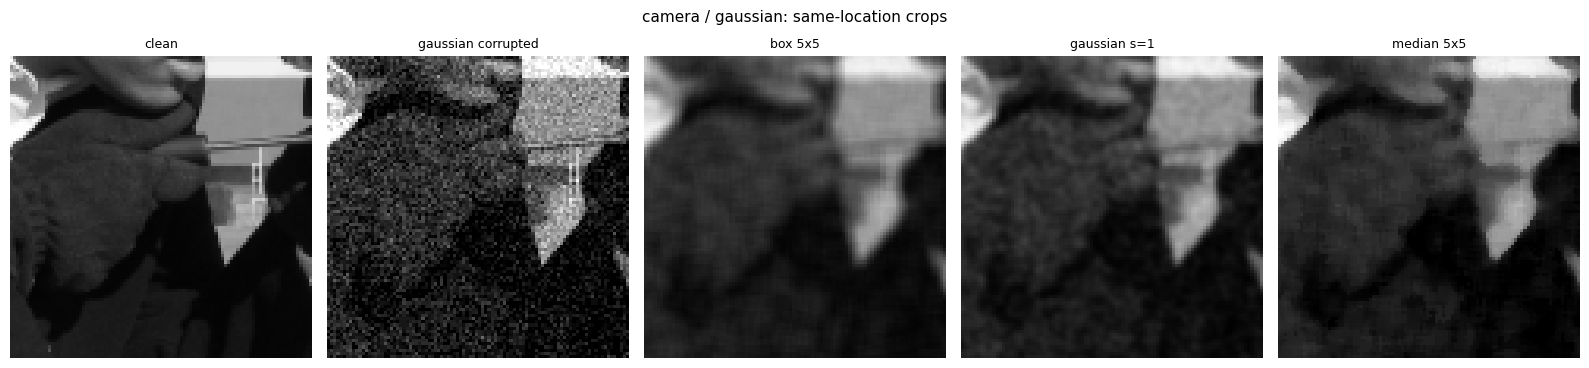

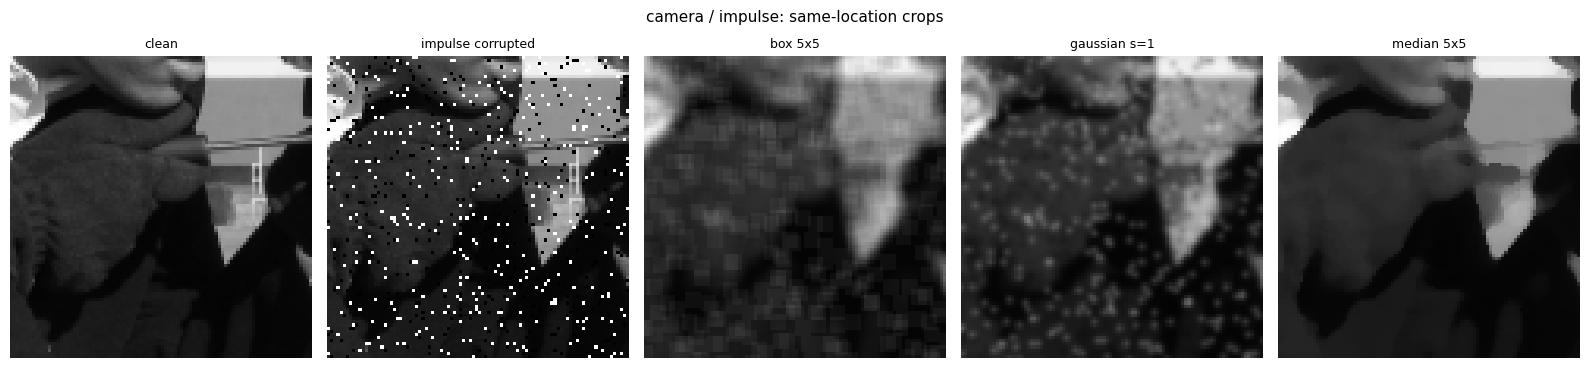

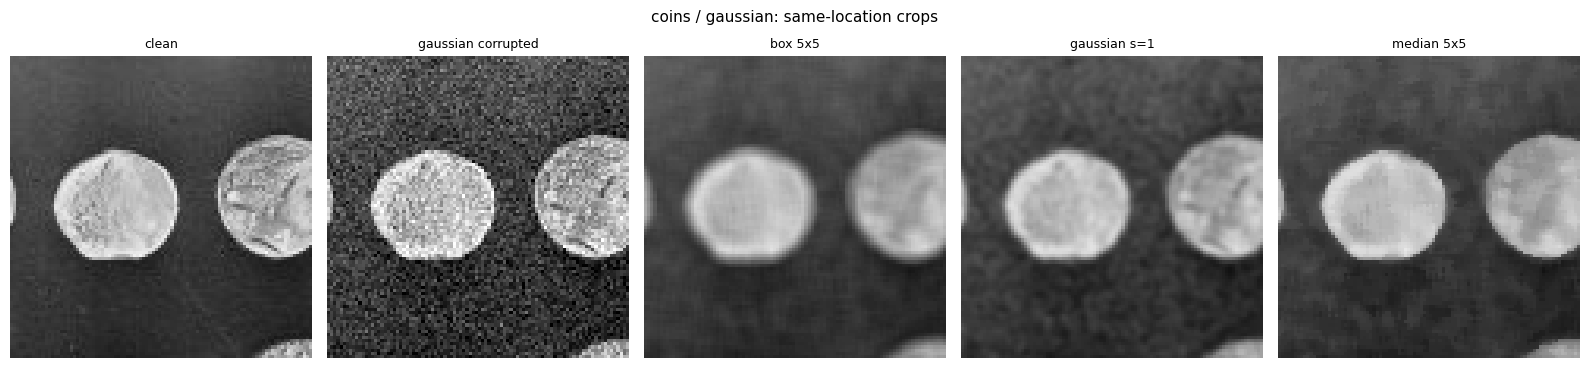

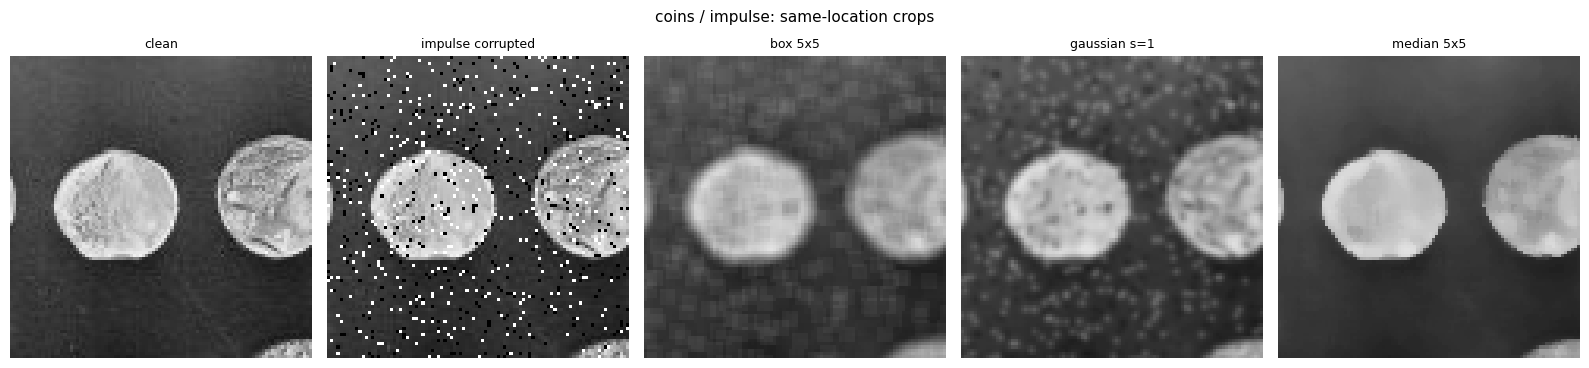

In [9]:
# 3c. Visual evidence at the same location for every condition.

for (name, corruption), outs in outputs.items():
    H.show_images(
        [H.crop(images[name], image_name=name),
         H.crop(corrupted[name][corruption], image_name=name)]
        + [H.crop(v, image_name=name) for v in outs.values()],
        ["clean", f"{corruption} corrupted"] + list(outs),
        suptitle=f"{name} / {corruption}: same-location crops")
plt.show()

### 3d. Evidence and interpretation

**What happened? (evidence)**
> The visual evidence evaluates three filtering methods across two images corrupted by Gaussian and impulse noise. The test images ("camera" and "coins") were first degraded by both noise types. They were then processed using a 5x5 box filter, a Gaussian filter (σ = 1\), and a 5x5 median filter before the final outputs were displayed.

> There is an accompanying table that describes the characteristics of the visual evidence (the photo being corrupted, how it is being corrupted, and the PSNR values for each filter). The higher the PSNR value, the closer it is to faithfully recreating the clean image.

**Did the evidence support your prediction?**

> Using the PSNR values to support my predictions, they were both correct.
For the Gaussian corruption, the Gaussian filter has the highest PSNR value for both images.
Regarding the salt-and-pepper/impulse corruption, the median filter both visually and statistically performed better than the box and Gaussian filters.

**What assumption or expectation should be revised?**

> No assumptions or expectations from the initial prediction need to be revised.

**What trade-off remains even for the best-performing method?**

> While Gaussian and box filters reduce noise by smoothing an image, they do so at the expense of sharp edges and high-frequency details. In contrast, median filters excel at removing impulse noise and preserving major boundaries, but they sacrifice small features and thin lines, which the algorithm rejects as outliers.

**What visible artifacts distinguish the outputs?** Point to specific structures in the
crops — edges, fine texture, isolated bright or dark points — rather than describing the
images as generally "better" or "worse".

> The visible artifacts are most prominent when the box and Gaussian filters were applied to the impulse noise. This resulted in isolated bright or dark points and fine textures not present in the original. The median filter tended to blur fine details and leave thin edges where small features previously existed.

---

# Part 4 — Parameter sensitivity and failure · **25 points**

*Required report section: **Analysis and Parameter Sensitivity**.*

This is the largest analytical part of the project. Three controlled sweeps, each
following the same loop: predict, sweep one parameter with everything else fixed, gather
quantitative and visual evidence, compare with your prediction, interpret.

## 4.1 Gaussian filter on Gaussian-corrupted images

Required values: **sigma = 0.5, 1.0, 1.5, 2.0**, all other conditions fixed.

### Prediction

How do you expect PSNR to behave across this sweep — monotone, or with an interior best
value? And do you expect the numerically best sigma to also be the one you would choose
by eye?

> The asusmption is made that the PSNR will vary across the sweep and will have an interior best value, likely at a sigma value of 1.0. I do not anticipate the best numerical value to be the one I choose by eye.

In [10]:
# 4.1a Gaussian sigma sweep on the Gaussian-corrupted images.

SIGMAS = [0.5, 1.0, 1.5, 2.0]
sigma_rows = []
sigma_outputs = {}
for name, img in images.items():
    noisy_img = corrupted[name]["gaussian"]
    row = [name, H.psnr(img, noisy_img)]
    for s in SIGMAS:
        out = gaussian_filter(noisy_img, sigma=s, mode=H.DEFAULT_BOUNDARY)
        sigma_outputs[(name, s)] = out
        row.append(H.psnr(img, out))
    sigma_rows.append(row)

sigma_table = H.results_table(sigma_rows,
                              ["image", "no filter"] + [f"sigma={s}" for s in SIGMAS])
print(sigma_table)

| image | no filter | sigma=0.5 | sigma=1.0 | sigma=1.5 | sigma=2.0 |
|---|---|---|---|---|---|
| camera | 22.241 | 25.758 | 27.906 | 26.744 | 25.617 |
| coins | 22.021 | 25.395 | 26.151 | 24.632 | 23.496 |


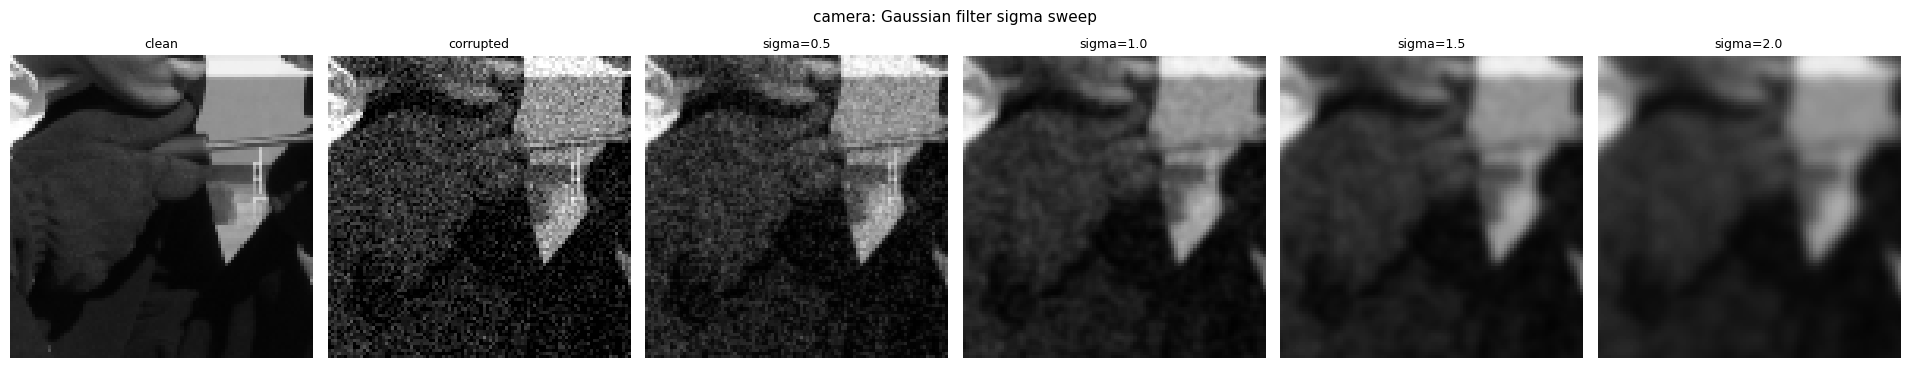

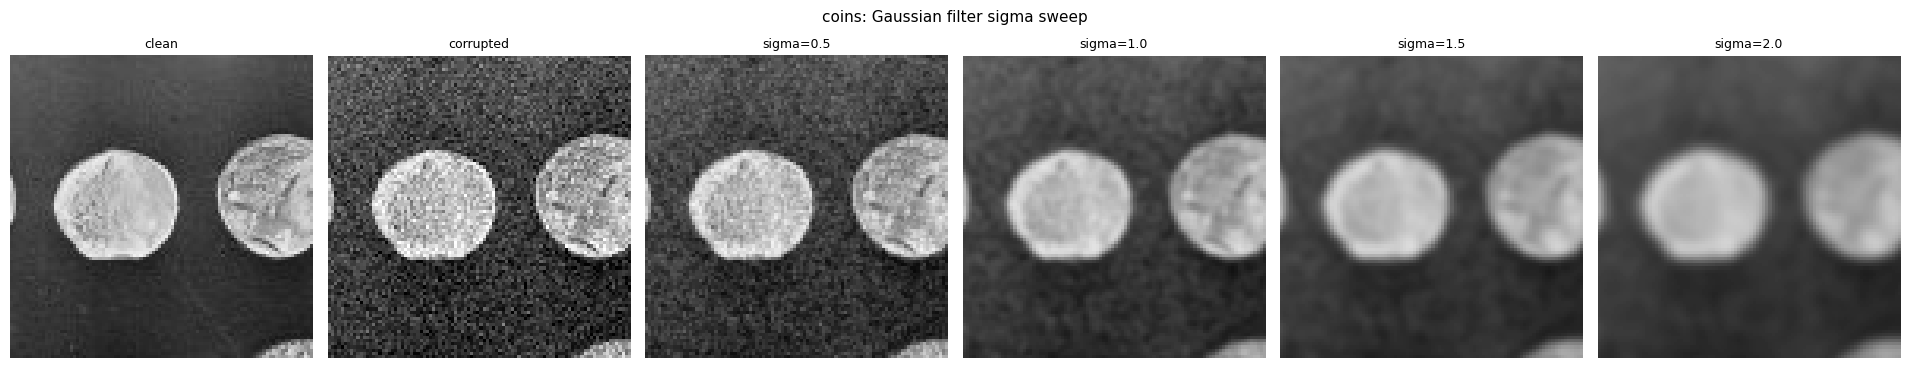

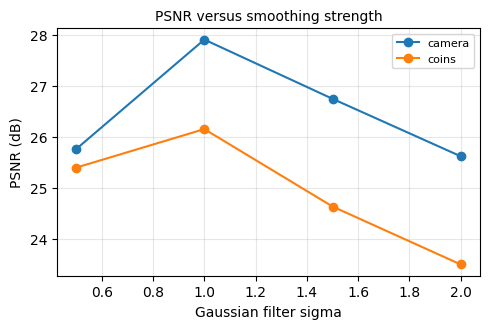

In [11]:
# 4.1b Visual evidence for the sigma sweep: same-location crops.

for name in images:
    H.show_images(
        [H.crop(images[name], image_name=name),
         H.crop(corrupted[name]["gaussian"], image_name=name)]
        + [H.crop(sigma_outputs[(name, s)], image_name=name) for s in SIGMAS],
        ["clean", "corrupted"] + [f"sigma={s}" for s in SIGMAS],
        suptitle=f"{name}: Gaussian filter sigma sweep")
plt.show()

# A PSNR-versus-sigma plot makes the trend easier to argue about than a table alone.
fig, ax = plt.subplots(figsize=(5.0, 3.4))
for name, img in images.items():
    ax.plot(SIGMAS, [H.psnr(img, sigma_outputs[(name, s)]) for s in SIGMAS],
            marker="o", label=name)
ax.set_xlabel("Gaussian filter sigma")
ax.set_ylabel("PSNR (dB)")
ax.set_title("PSNR versus smoothing strength", fontsize=10)
ax.grid(alpha=0.3); ax.legend(fontsize=8)
fig.tight_layout()
plt.show()

### 4.1c Analysis

**What happened? (evidence)**

> Two corrupted images ("camera" and "coins") were processed using a Gaussian filter at different sigma values. A corresponding plot tracks the resulting PSNR values as sigma increases. Both the visual evidence and the plot confirm that a sigma value of 1.0 performs best, maximizing noise reduction while successfully preserving image edges.

**Did the evidence support your prediction?**

> The evidence visually and statistically agreed with my prediction. According to the plot, the maximum values of PSNR occur at σ = 1. There is no conflicts with the initial prediction.

**What assumption or expectation should be revised?**

> Noise suppression improves as σ increases across the sweep, but at higher values this improvement comes at the cost of excessive blurring. Fine details, such as the texture on the coins and the folds in the clothing, become progressively less visible as σ increases. PSNR increases with σ up to a peak at σ = 1, then continuously decreases, indicating that PSNR has an interior maximum. The numerically best σ (1.0, by PSNR) was not the σ I would choose visually, since noise appears to be still present. This disagreement shows that PSNR alone is not sufficient evidence of a filter's success. As σ grows, image structure as a whole becomes increasingly blurred, with edges and fine texture progressively lost as raw noise is suppressed.

## 4.2 Median filter on impulse-corrupted images

Required supports: **3 x 3, 5 x 5, 7 x 7**, all other conditions fixed.

### Prediction

> While a larger median window may help at certain impulse rates, it will not always be beneficial at 8% impulse rate.

In [12]:
# 4.2a Median support sweep on the impulse-corrupted images.

SUPPORTS = [3, 5, 7]
median_rows = []
median_outputs = {}
for name, img in images.items():
    noisy_img = corrupted[name]["impulse"]
    row = [name, H.psnr(img, noisy_img)]
    for k in SUPPORTS:
        out = median_filter(noisy_img, size=k, mode=H.DEFAULT_BOUNDARY)
        median_outputs[(name, k)] = out
        row.append(H.psnr(img, out))
    median_rows.append(row)

median_table = H.results_table(median_rows,
                               ["image", "no filter"] + [f"{k}x{k}" for k in SUPPORTS])
print(median_table)

| image | no filter | 3x3 | 5x5 | 7x7 |
|---|---|---|---|---|
| camera | 15.724 | 29.778 | 27.729 | 26.174 |
| coins | 16.065 | 28.043 | 26.155 | 25.108 |


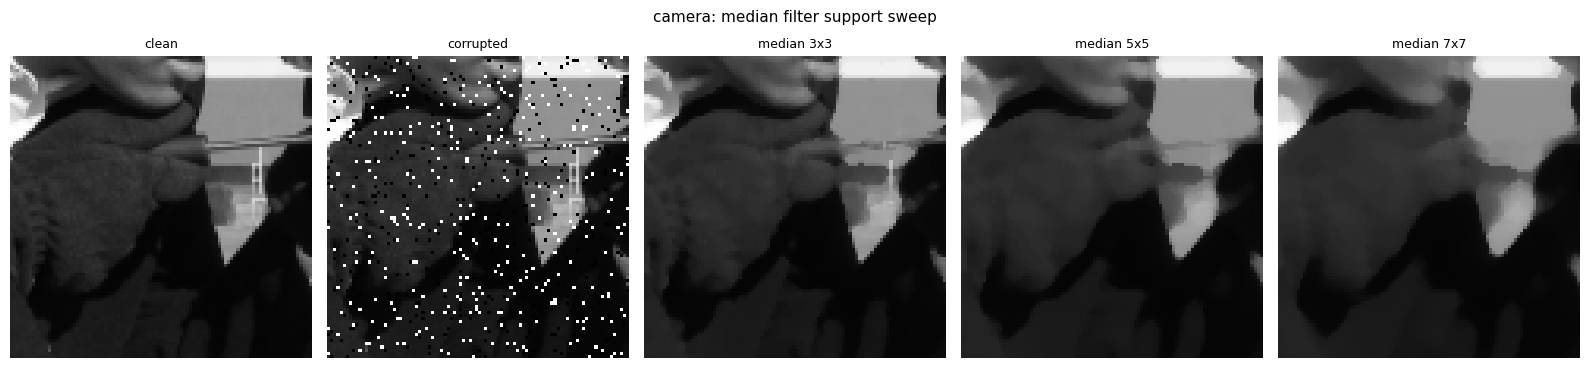

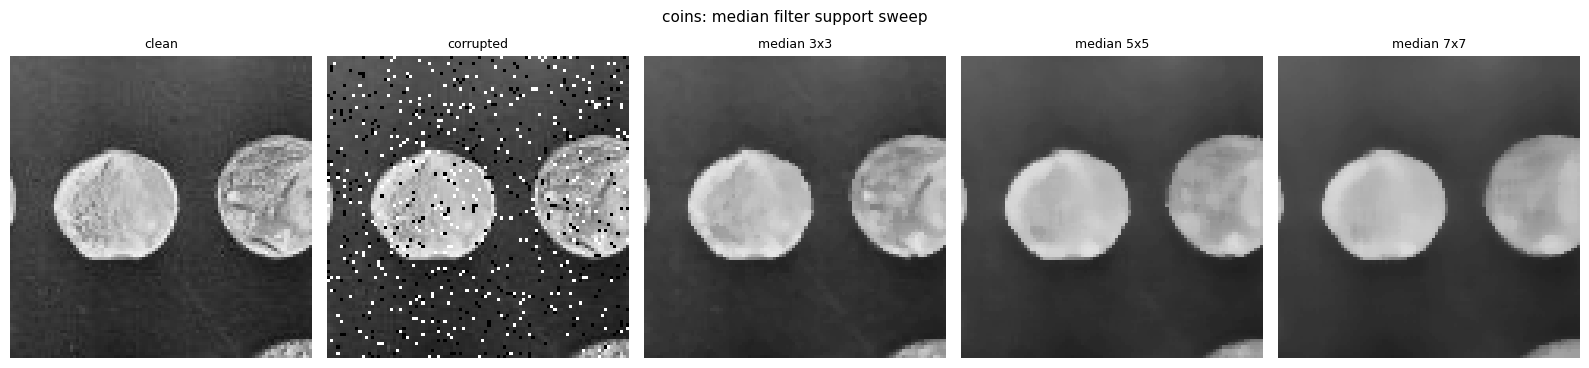

In [13]:
# 4.2b Visual evidence for the median sweep.

for name in images:
    H.show_images(
        [H.crop(images[name], image_name=name),
         H.crop(corrupted[name]["impulse"], image_name=name)]
        + [H.crop(median_outputs[(name, k)], image_name=name) for k in SUPPORTS],
        ["clean", "corrupted"] + [f"median {k}x{k}" for k in SUPPORTS],
        suptitle=f"{name}: median filter support sweep")
plt.show()

### 4.2c Analysis

**What happened? (evidence)**
> Two images ("camera" and "coins") are corrupted using impulse noise, then swept over with median filters of increasing size. Visually, both images denoise effectively with the smallest filter, then grow progressively blurrier as the filter size increases. The PSNR values follow this same pattern as the 3x3 median filter achieves the highest PSNR, with progressively larger filters showing a slight decline.

**Did the evidence support your prediction?**
> Both the visual and statistical evidence supported my original prediction. While a larger median filter may be more effective at higher impulse noise rates, larger filters are not universally optimal. In this case, the smaller filters achieved higher PSNR values and appeared visually less blurry.

**What assumption or expectation should be revised?**

> I originally assumed larger filters simply removed more noise, making them more efficient when more noise is present. The evidence shows an inverse relationship instead where larger filters suppress more noise but preserve less detail. This is due to the fact that bigger neighborhood start treating real structure like outliers. Past a certain size, this becomes over-smoothing, where structures are destroyed rather than just noise. At filter size 3×3, no residual impulses are visible. This shows filter size should not be directly related to amount of noise and that a balance should be achieved.

## 4.3 Boundary mini-experiment

The default boundary convention for this project is `reflect`. Here you compare it
against `constant` (zero padding) for **one** representative filtering condition of your
choice — state which one you chose.

### Prediction

> I chose the reflection boundary convention. I anticipate that the output image will differ on the edges of the image and by a significant amount.

In [14]:
# 4.3a Compare two boundary conventions for one filtering condition.
#      State your chosen condition in the Markdown cell below.

bname = "camera"
bclean = images[bname]
bnoisy = corrupted[bname]["gaussian"]
BSIGMA = 2.0            # a large support makes the boundary effect visible

out_reflect  = gaussian_filter(bnoisy, sigma=BSIGMA, mode="reflect")
out_constant = gaussian_filter(bnoisy, sigma=BSIGMA, mode="constant", cval=0.0)

print(H.results_table(
    [["reflect",  H.psnr(bclean, out_reflect)],
     ["constant (zero)", H.psnr(bclean, out_constant)]],
    ["boundary mode", "PSNR (dB)"]))

difference = np.abs(out_reflect - out_constant)
print("\nlargest absolute difference anywhere :", round(float(difference.max()), 6))
print("largest absolute difference in the image interior :",
      round(float(difference[20:-20, 20:-20].max()), 6))

| boundary mode | PSNR (dB) |
|---|---|
| reflect | 25.617 |
| constant (zero) | 24.632 |

largest absolute difference anywhere : 0.501578
largest absolute difference in the image interior : 0.0


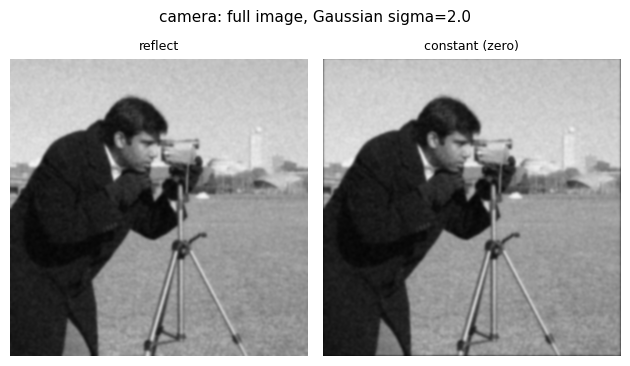

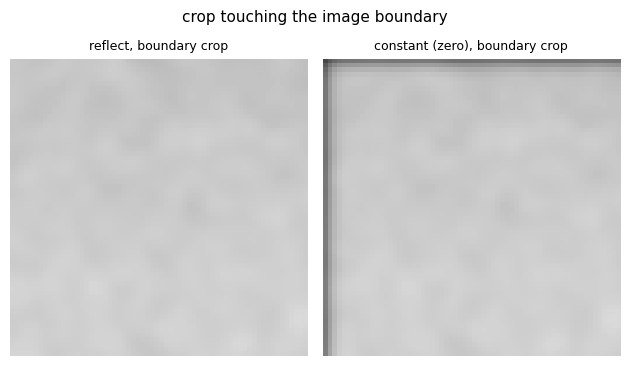

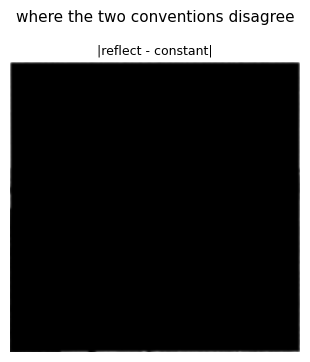

In [15]:
# 4.3b Required evidence: the full image under both conventions, and a crop that
#      touches the image boundary.

H.show_images([out_reflect, out_constant],
              ["reflect", "constant (zero)"],
              suptitle=f"{bname}: full image, Gaussian sigma={BSIGMA}")
H.show_images([H.boundary_crop(out_reflect), H.boundary_crop(out_constant)],
              ["reflect, boundary crop", "constant (zero), boundary crop"],
              suptitle="crop touching the image boundary")
H.show_images([difference], ["|reflect - constant|"], vmin=0.0, vmax=float(difference.max()),
              suptitle="where the two conventions disagree")
plt.show()

### 4.3c Interpretation

State which filtering condition you used, then explain what you see.

> I used the reflection boundary convention. As shown in the evidence above, this approach preserves an identical image at the center without introducing the border artifacts seen in the zero-padding method.

Then argue this claim in your own words, using your evidence:

> **Boundary handling is part of the definition of the finite-image operation, not merely
> a software implementation detail.**

> Boundary handling is an essential part of the definition of a finite-support convolution. The convolution sum requires a value for every input position the kernel touches, but near the edges some of these positions fall outside the stored array. Without a stated boundary convention, the operation is undefined at those pixels. It is not something to be added afterward as a detail.

## 4.4 Part 4 conclusion

Argue, from your own evidence, why there is no universally best smoothing strength — and
state the general principle that connects all three sweeps.

> The optimal smoothing strength is highly dependent on both the amount of noise present and what the task requires (noise suppression, structure preservation, or some balance of the two). From evidence above, a Gaussian filter with σ = 1.5 effectively removes noise from the "camera" image without much visible cost, but applying that same σ to the "coins" image erases important structure and detail. The general principle connecting all three sweeps is that smoothing strength trades noise suppression against detail preservation, and where that trade-off is best balanced depends on the specific image and task, not a fixed, universally optimal σ.

---

# Part 5 — Learn the Gaussian smoothing kernel · **20 points**

*Required report section: **Analysis and Parameter Sensitivity**.*

Everything so far used coefficients that someone specified explicitly: a box kernel is
constant, a Gaussian kernel comes from a formula, a median is a rule rather than a set of
weights. This part changes exactly one thing: **where the 25 coefficients of a 5 x 5
kernel come from.**

The model is one 2-D convolution layer — one input channel, one output channel, kernel
size 5 x 5, no bias. That is **25 learnable numbers and nothing else**. You are given the
patch construction, the model definition, the optimizer, the training loop, and the
evaluation helpers. You are *not* asked to implement backpropagation, write an optimizer,
or design a network.

**The learning problem.**

| | |
|---|---|
| Input | a clean image patch |
| Target | that same patch after the analytical 5 x 5 Gaussian smoother, `sigma_target = 1.0` |
| Learnable parameters | the 25 kernel coefficients |
| Fixed before training | the convolutional form, the 5 x 5 support, spatial sharing of coefficients, the valid-region boundary convention, the training patches, the target operator, the loss, the initialization, the optimizer |
| Loss | mean squared error between the learned filter output and the analytical-Gaussian target output |
| Training images | `camera`, `coins`, `moon` |
| Held-out image | `astronaut`, converted to grayscale float in `[0, 1]` |

**Boundary convention during training.** The convolution uses no padding, and each
target is produced under the same valid-region convention, so boundary artifacts are
never the learning target.

In [16]:
# 5a. Read this cell before running it. The model is short on purpose.

import inspect
import learned_kernel as LK

print(inspect.getsource(LK.LearnedSmoother))

class LearnedSmoother(nn.Module):
    """A single 2-D convolution layer with one 5 x 5 kernel and no bias."""

    def __init__(self, kernel_size: int = KERNEL_SIZE):
        super().__init__()
        self.conv = nn.Conv2d(
            in_channels=1,
            out_channels=1,
            kernel_size=kernel_size,
            padding=0,        # valid region only: boundary is handled explicitly
            bias=False,
        )

    def forward(self, x):
        return self.conv(x)

    def kernel(self) -> np.ndarray:
        """Return the current 5 x 5 coefficients as a NumPy array."""
        return self.conv.weight.detach().cpu().numpy()[0, 0].copy()



In [17]:
# 5b. Build the deterministic dataset and the model, and confirm the parameter count.

data = LK.build_dataset()
model = LK.make_model()

print("training patches      :", tuple(data["x_train"].shape))
print("validation patches    :", tuple(data["x_val"].shape))
print("target (valid) region :", tuple(data["y_train"].shape))
print("training images       :", data["image_names"])
print("seed                  :", data["seed"])
print("learnable parameters  :", sum(p.numel() for p in model.parameters()))

training patches      : (480, 1, 32, 32)
validation patches    : (120, 1, 32, 32)
target (valid) region : (480, 1, 28, 28)
training images       : ('camera', 'coins', 'moon')
seed                  : 6640
learnable parameters  : 25


### 5c. State the learning problem in your own words, and predict

Before training, answer each of these in one line:

1. What is the input?  → The crop of an uncorrupted image.
2. What is the target?  → The same cropped image after being blurred by a defined Gaussian blur.
3. Which quantities are learned?  → The 25 coefficients that make up the 5x5 kernel.
4. Which quantities are fixed before training begins?  → The convolution equation, boundary handling, kernel size, the images used for training, the target operator, the loss, the initialization/optimization of the learning process, and the spatial sharing of the coefficients.
5. What does the loss measure?  → The mean squared error between the learned target output and the set Gaussian target output. This essentially calculates the mathematical difference between the two outputs.

**Prediction.** What do you expect the learned 5 x 5 kernel to look like once training
converges? Be specific: sign of the coefficients, where the largest values sit, what the
coefficients should sum to, and what symmetry you expect. Say *why* you expect that.

> The learned kernel should have all positive coefficients, since the target Gaussian itself has no negative values. The coefficients should sum to 1, as the filter should not brighten or darken the image. The largest value should be at the center, since the Gaussian weights nearby pixels more heavily than distant ones. The kernel should also be symmetric in all directions (horizontal, vertical, and diagonal) since the Gaussian's weight depends on distance from the center.

In [18]:
# 5d. Train. This is full-batch Adam on CPU and typically takes 30-120 seconds, depending on the CPU.

log = LK.train_kernel(model, data)

step     0   train MSE 7.381e-01   val MSE 5.771e-02
step   500   train MSE 8.335e-05   val MSE 8.140e-05
step  1000   train MSE 1.043e-05   val MSE 9.999e-06
step  1500   train MSE 1.142e-06   val MSE 1.073e-06
step  2000   train MSE 8.200e-08   val MSE 7.378e-08
step  2500   train MSE 6.963e-05   val MSE 7.390e-05
step  3000   train MSE 3.515e-10   val MSE 3.042e-10
training finished in 122.1 s on CPU


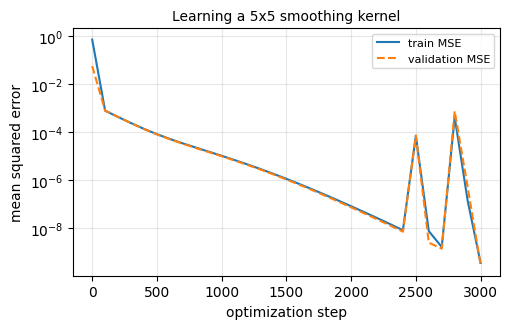

In [19]:
# 5e. Loss curve.

LK.plot_loss(log, "Learning a 5x5 smoothing kernel")
plt.show()

learned kernel coefficients:
[[0.00306 0.0132  0.02199 0.01333 0.00292]
 [0.0131  0.05987 0.09819 0.05962 0.0134 ]
 [0.02222 0.09797 0.16234 0.09828 0.02185]
 [0.01301 0.06003 0.09802 0.05974 0.01335]
 [0.00313 0.01306 0.02213 0.01322 0.00297]]

analytical target kernel coefficients:
[[0.00297 0.01331 0.02194 0.01331 0.00297]
 [0.01331 0.05963 0.09832 0.05963 0.01331]
 [0.02194 0.09832 0.1621  0.09832 0.02194]
 [0.01331 0.05963 0.09832 0.05963 0.01331]
 [0.00297 0.01331 0.02194 0.01331 0.00297]]


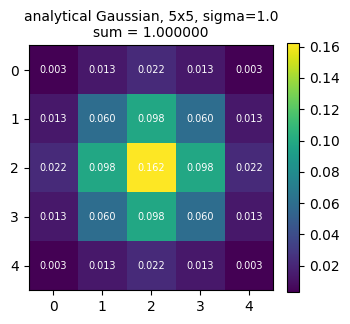

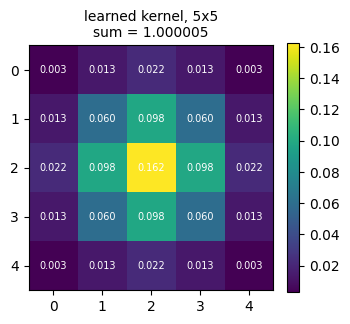

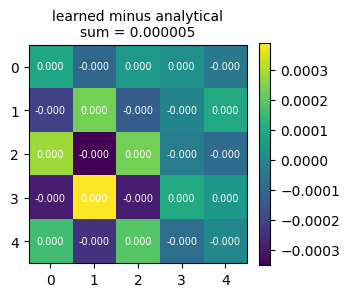

In [20]:
# 5f. Compare the learned kernel with the analytical Gaussian it was asked to reproduce.

K_learned = model.kernel()
K_target = data["kernel_target"]

print("learned kernel coefficients:")
print(np.round(K_learned, 5))
print("\nanalytical target kernel coefficients:")
print(np.round(K_target, 5))

H.show_kernel(K_target, "analytical Gaussian, 5x5, sigma=1.0")
H.show_kernel(K_learned, "learned kernel, 5x5")
H.show_kernel(K_learned - K_target, "learned minus analytical")
plt.show()

In [21]:
# 5g. Quantitative comparison: coefficient sum, distance, and approximate symmetry.

report = LK.kernel_report(K_learned, K_target)
print(H.results_table([[k, v] for k, v in report.items()], ["measure", "value"]))

| measure | value |
|---|---|
| learned_sum | 1.000 |
| target_sum | 1.000 |
| max_abs_difference | 3.915e-04 |
| l2_distance | 9.427e-04 |
| relative_l2_distance | 0.0033 |
| horizontal_symmetry_error | 3.745e-04 |
| vertical_symmetry_error | 1.633e-04 |
| transpose_symmetry_error | 4.086e-04 |


held-out image : astronaut (512, 512)
mean squared difference, learned vs analytical output : 1.855e-10
largest absolute difference                           : 4.240e-04


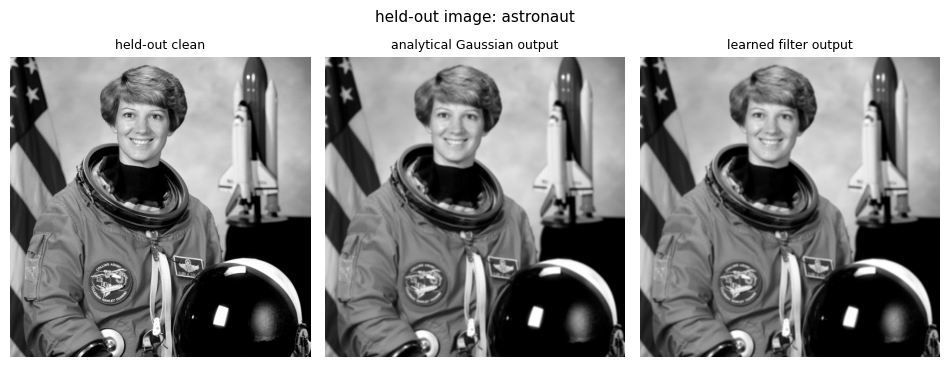

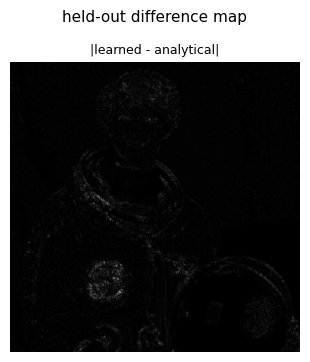

In [22]:
# 5h. Held-out evaluation: an image the kernel was never trained on.

held = LK.held_out_evaluation(model, K_target)
print("held-out image :", held["image"], held["shape"])
print("mean squared difference, learned vs analytical output :", f"{held['mse']:.3e}")
print("largest absolute difference                           :",
      f"{held['max_abs_difference']:.3e}")

H.show_images([held["clean"], held["analytical_output"], held["learned_output"]],
              ["held-out clean", "analytical Gaussian output", "learned filter output"],
              suptitle=f"held-out image: {held['image']}")
H.show_images([np.abs(held["difference"])], ["|learned - analytical|"],
              vmin=0.0, vmax=float(np.abs(held["difference"]).max()),
              suptitle="held-out difference map")
plt.show()

### 5i. Compare the result with your prediction

**What happened? (evidence)**
> The evidence begins with a plot showing the MSE value dropping as the optimization steps increasing. This is stating that the more iterations of the learning process is decreasing the mathematical difference between the learned and defined Gaussian kernel.

The evidence following shows the defined Gaussian kernel, the learned kernel, and the differences between them. While the values shown in both kernels are the exact same, the sum of the learned kernel is slightly higher (1.000005) than the defined Gaussian (1.0). Given more optimization steps, the numbers are likely to get closer in value.

The final section of the evidence is a visual model comparing the analytical Gaussian output and the learned output to the held-out clean image. Also included, and most importantly, is a held-out difference map between the learned and analytical showing the slight differences between the two images.

**Did the evidence support your prediction?**

> The evidence did support my initial prediction. Evident in the display of kernel coefficients, the values of the learned kernel is identical to the analytical kernel. The only evidence that did not support my initial claim was the sum of the learned kernel was 1.000005 and not 1.0 exactly.

**What assumption or expectation should be revised?**

> The learned kernel closely matches the analytical Gaussian's expected properties. It posseses near-perfect symmetry and coefficient values very close to the target. However, there is one small discrepancy being the coefficients sum to 1.00005 instead of exactly 1.0. Thus, the assumption to revise is expecting the learned kernel to exactly reproduce the analytical Gaussian's properties. In practice, it can only approximate them, converging very close to but not exactly onto values like a sum of 1.

### 5j. What stayed the same, and what changed?

**What stayed the same** — say why each of these was true both for the explicitly
designed Gaussian filter of Part 2 and for the learned filter here:

* a local neighborhood operation;
* a convolutional form;
* a fixed support;
* spatial sharing of coefficients across the image;
* finite-image boundary assumptions.

> All five properties held for both filters because they are structural choices built into the model's design before training began. They define the fixed convolutional form within which optimization operates. Training only adjusts the 25 coefficient values inside that structure. It has no mechanism to alter the neighborhood size, the weighted-sum form, the coefficient sharing across space, or the boundary handling, since none of these are learnable parameters. They are fixed by how the model was set up.

**What changed** — exactly one thing. State it precisely.

> The only learnable parameter in this experiment is the kernel coefficient values.

### 5k. Learned does not mean assumption-free

Learning did not remove assumptions; it relocated them. List the assumptions that
entered through the *training setup* rather than through a formula — training examples,
target, model family, loss, initialization, optimization — and for each one, name a
change to it that would have produced a different learned kernel.

> Training examples: Trained on "camera", "coins", and "moon". Using only low-texture images instead would give the loss little signal to distinguish a Gaussian shape from other kernels that also average flat regions well.

> Target: Target was the analytical Gaussian, σ = 1.0. A larger target σ would require a wider, flatter kernel; a box-filter target would push coefficients toward uniform weighting instead of a center peak.

> Model family: Model was a 5x5 linear convolutional kernel. If things had changed, for example, a 3x3 kernel couldn't represent the full 5x5 spatial extent. A median filter couldn't be trained this way at all, since it does not have any learned parameters.

> Loss: MSE penalizes large errors much more than small ones. Using another metric such as retained structure contrast instead would penalize for loss of structure and have effected how the model trained.

> Initialization: Starting weights were set before training began. A far-off initialization (e.g., random high numbers) could require more steps to converge, or land on a different final approximation given the same fixed training length.

> Optimization: Trained with gradient descent for a fixed number of steps. Fewer steps would leave coefficients further from the target (consistent with the 1.00005 sum); a different optimizer or learning rate could converge to a different final point.

---

# Part 6 — Module synthesis · **10 points**

*Required report section: **Responses to Analytical Questions**.*

Answer each question concisely and support it with the module's reasoning — and, where
relevant, with evidence you produced above. No new code is required for this part.

### A. Representation

Why can denoising reduce added corruption but not generally recover information already
lost through insufficient sampling or quantization?

> Denoising can reduce added noise because that corruption sits on top of intact signal information still present in the samples. However, if information was never captured, whether it be due to insufficient sampling or coarse quantization, no processing can recover distinctions that were never recorded. There is nothing in the data to recombine into the missing detail.

### B. Operator reasoning

Why is boundary handling part of the mathematical finite-image operation? How could two
otherwise identical implementations disagree if they use different boundary conventions?

> Boundary handling is an essential part of the mathematical finite-image operation. For example, convolution sum with finite-supports requires a value for every input term the kernel touches, including positions outside the stored array. Without a set convention, the operation is undefined at edges. Two implementations with identical kernels but different conventions (e.g., zero-padding vs. reflection) will therefore disagree at and near the boundary, even though their interior results match.

### C. Distribution versus spatial structure

Why is similarity between an output histogram and the clean-image histogram insufficient
evidence that the spatial image has been restored?

> A histogram only records how many pixels have each intensity value, not where they are located, so it carries no information about spatial arrangement. A clean image can be completely scrambled, destroying all semblence, while its histogram stays identical. A restored output could therefore match the clean histogram closely while still being spatially wrong.

### D. Filter design

Using your own P1 evidence, explain why filter selection depends on **both** the
corruption mechanism **and** the spatial structure you want to preserve.

> My P1 results showed Gaussian and box filters performed best on Case X (Gaussian noise) but worse on Case Y (impulse noise), while median filtering reversed this pattern — matching each filter's mechanism (averaging vs. outlier-rejection) to how each corruption type alters pixels. However, filter choice can't rest on corruption type alone. Gaussian/box filters blurred edges more than median did, so when preserving spatial structure matters, the best choice depends on both the corruption mechanism and how much edge or detail preservation the task requires.

### E. Forward transfer

If the filtered image were later used for derivative-based edge detection, why can
additional smoothing improve robustness to noise while eventually degrading edge
localization or fine structure?

> Smoothing before edge detection suppresses small, high-frequency pixel-to-pixel fluctuations caused by noise, which derivative operators would otherwise amplify into false edges. Real edges are also rapid intensity changes, so enough smoothing blurs and widens them too, making their exact location harder to pinpoint. There is an important balance where too little smoothing leaves noise-driven false edges, while too much degrades true edge localization.

---

# Conclusions

*Required report section: **Conclusions**.*

Summarize your key findings and the limitations you observed. Return to the central
project question and answer it in your own words, citing the specific evidence in this
notebook that supports your answer. State at least one thing your experiments could
*not* determine.

> This project found that filter effectiveness depends on matching mechanism to corruption. Gaussian and box filters best suppressed Gaussian noise (highest PSNR), while median best suppressed impulse noise while preserving edges. Every filter traded some form of detail for suppression, Gaussian/box blurred edges, median could erase small features. This confirms there is no universally best filter. The right choice depends on both corruption type and how much spatial detail the task requires preserving. However, these experiments could not determine how these filters perform on real-world noise, which is often complex, mixed, and unknown, unlike the controlled synthetic corruption used here.

---

# Optional research extension · **up to +10 points**

*Optional. Extra credit only — attempting this can never reduce your base grade.*

**Theme: how stable is the learned Gaussian kernel?**

Form a hypothesis about how *source-image diversity* affects the learned kernel, then
test it with one controlled comparison: 480 training patches drawn evenly from
`camera`, `coins`, and `moon` versus 480 training patches drawn from `camera` alone.
Reuse the exact same 120 validation patches in both conditions. Hold the seed, target,
model, initialization, optimizer, learning rate, loss, and number of steps fixed. Keep
`astronaut` untouched as the final held-out evaluation. The only intended change is the
diversity of the source images represented in the training patches. The helper samples
crop locations; 480 patches from `camera` is easily feasible, and spatial overlap among
patches is expected.

Compare: the learned coefficients, the distance to the analytical Gaussian, the held-out
output error, the training behavior, and what all of that says about generalization.

Credit follows: hypothesis → controlled experiment → evidence → interpretation →
limitations. Do not turn this into a larger network, an architecture search, a
classification task, or a backpropagation implementation.

### Hypothesis

> _Replace this line with your hypothesis and the reasoning behind it._

In [23]:
# Bonus. A controlled source-image-diversity comparison.
# Both conditions use 480 training patches and the exact same validation tensors.
# Everything else (seed, target, model, optimizer, steps) stays at its default.

# conditions = [
#     ("three images", ("camera", "coins", "moon")),
#     ("one image", ("camera",)),
# ]
# validation_images = ("camera", "coins", "moon")
# validation_seed = H.SEED + 1
# bonus_results = []
# fixed_x_val = None
# fixed_y_val = None
# for label, names in conditions:
#     d = LK.build_dataset(
#         image_names=names, n_train=480, n_val=120,
#         validation_image_names=validation_images,
#         validation_seed=validation_seed,
#     )
#     if fixed_x_val is None:
#         fixed_x_val = d["x_val"].numpy().copy()
#         fixed_y_val = d["y_val"].numpy().copy()
#     else:
#         assert np.array_equal(fixed_x_val, d["x_val"].numpy())
#         assert np.array_equal(fixed_y_val, d["y_val"].numpy())
#     m = LK.make_model()
#     log_bonus = LK.train_kernel(m, d, verbose=False)
#     r = LK.kernel_report(m.kernel(), d["kernel_target"])
#     h = LK.held_out_evaluation(m, d["kernel_target"])
#     bonus_results.append([
#         label, str(names), d["n_train"], log_bonus.val_loss[-1],
#         r["relative_l2_distance"], h["mse"],
#     ])
#
# print(H.results_table(bonus_results,
#       ["condition", "training images", "patches", "fixed-val MSE",
#        "relative L2 to analytical", "held-out MSE"]))

### Bonus evidence, interpretation, and limitations

> _Replace this line._

---

# AI Use Declaration and Reflection

This project is individual work. AI tools may be used as a thinking aid within the
course policy — clarifying a concept, clarifying a library call, checking your reasoning,
exploring alternative approaches, or diagnosing a problem in code you wrote. AI tools may
not generate the implementation, the required analysis, the synthesis responses,
derivations, report prose, or experimental results that you submit as your own work.
All external libraries, code snippets, and AI-generated content used as reference must be
cited both in your code and here.

Complete **one** of the following.

**If you did not use AI tools on this project:**

> _State that here._

**If you did use AI tools:**

1. Which tool(s)?

   > I primarily used the Claude LLM.

2. One way AI supported your thinking:

   > Claude was used to rephrase questions and clarify/connect concepts.

3. One way you independently checked, corrected, or verified what it produced:

   > If the information was not referenced in Module 1, it was not taken or considered. If the information/material was referenced in Module 1, it was cross-referenced with the textbook readings and lecture companions.

No prompt logs, transcripts, screenshots, or timestamps are requested.

---

# Before you submit

1. Fill in **Name** and **UID** at the top of this notebook.
2. Complete every required prediction, evidence, interpretation, and synthesis response.
3. Kernel → **Restart Kernel and Run All Cells**, and let it finish without errors.
4. Check that every required figure and table is visible in the output.
5. Save the notebook.
6. Export the executed notebook to a static `driver.pdf` (see the project PDF,
   Submission Instructions).
7. Run `python check_submission.py` in the project folder and resolve anything it flags.
8. Create `<UID>-p1.zip` containing `driver.ipynb`, `driver.pdf`, `p1_helpers.py`,
   `learned_kernel.py`, `requirements.txt`, and any additional Python files your work
   needs in order to reproduce.
9. Submit the single ZIP to Canvas.